## 01 - Data Preprocessing

This notebook performs the full data preprocessing pipeline for the UCI Online Retail dataset to prepare historical UK sales data for demand forecasting.

## Step 1 — Load dataset
First, we load the dataset and verify its existence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path(r"C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data\Online Retail.xlsx")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH.resolve()}")

print("File path:", DATA_PATH.resolve())
df = pd.read_excel(DATA_PATH)
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
df.head()

File path: C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data\Online Retail.xlsx

Dataset shape: (541909, 8)

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
 InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Step 2 — Initial data quality analysis
Check rows, columns, missing values, duplicates, unique values, and descriptive statistics. We won't delete missing values just yet without explaining.

In [2]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique values for important columns:")
for col in ['StockCode', 'Country', 'CustomerID']:
    print(f"  {col}: {df[col].nunique()}")
    
print("\nDescriptive statistics:")
display(df.describe(include='all').T)

Number of rows: 541909
Number of columns: 8

Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Unique values for important columns:
  StockCode: 4070
  Country: 38
  CustomerID: 4372

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 3 — Select the single-shop historical data
Since our project represents a single shop, we use only United Kingdom transactions as our source.

In [3]:
print("Rows before filtering:", len(df))
df_uk = df[df["Country"] == "United Kingdom"].copy()
print("Rows after filtering (UK only):", len(df_uk))
print("Number of products:", df_uk["StockCode"].nunique())
print("Date range:", df_uk["InvoiceDate"].min(), "to", df_uk["InvoiceDate"].max())

# Drop Country column as it's no longer needed
df_uk.drop(columns=["Country"], inplace=True)

Rows before filtering: 541909
Rows after filtering (UK only): 495478
Number of products: 4065
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:49:00


## Step 4 — Remove cancelled transactions
Invoices beginning with 'C' represent cancellations.

In [4]:
cancelled_mask = df_uk["InvoiceNo"].astype(str).str.startswith("C")
print("Number of cancelled transactions:", cancelled_mask.sum())
df_uk = df_uk[~cancelled_mask].copy()
print("Rows remaining after removing cancellations:", len(df_uk))

Number of cancelled transactions: 7856
Rows remaining after removing cancellations: 487622


## Step 5 — Remove invalid transactions
Remove records with Quantity <= 0 or UnitPrice <= 0.

In [5]:
invalid_qty = (df_uk["Quantity"] <= 0).sum()
invalid_price = (df_uk["UnitPrice"] <= 0).sum()

print(f"Records with Quantity <= 0: {invalid_qty}")
print(f"Records with UnitPrice <= 0: {invalid_price}")

df_uk = df_uk[(df_uk["Quantity"] > 0) & (df_uk["UnitPrice"] > 0)].copy()
print("Rows remaining after cleaning invalid transactions:", len(df_uk))

Records with Quantity <= 0: 1336
Records with UnitPrice <= 0: 2499
Rows remaining after cleaning invalid transactions: 485123


## Step 6 — Handle missing values
For demand prediction, StockCode, InvoiceDate, and Quantity are required. 
CustomerID and Description are not strictly required, so we won't delete valid rows just because they lack a CustomerID.

In [6]:
missing_before = df_uk[['StockCode', 'InvoiceDate', 'Quantity']].isnull().sum()
print("Missing values in required columns before handling:\n", missing_before)

df_uk.dropna(subset=['StockCode', 'InvoiceDate', 'Quantity'], inplace=True)
print("Rows remaining after removing missing essential fields:", len(df_uk))

Missing values in required columns before handling:
 StockCode      0
InvoiceDate    0
Quantity       0
dtype: int64
Rows remaining after removing missing essential fields: 485123


## Step 7 — Remove duplicates
Remove duplicate transaction records to avoid double-counting sales.

In [7]:
duplicates = df_uk.duplicated().sum()
print("Number of duplicates removed:", duplicates)
df_uk.drop_duplicates(inplace=True)
print("Rows remaining:", len(df_uk))

Number of duplicates removed: 5138
Rows remaining: 479985


## Step 8 — Clean product identifiers
Convert StockCode to string and remove unnecessary whitespace.

In [8]:
df_uk["StockCode"] = df_uk["StockCode"].astype(str).str.strip()
print("Number of unique products:", df_uk["StockCode"].nunique())
print("Sample product codes:", df_uk["StockCode"].sample(5, random_state=42).tolist())

Number of unique products: 3916
Sample product codes: ['22662', '22411', '23208', '22578', '15039']


## Step 9 — Convert date/time
Extract the calendar date from InvoiceDate to enable daily aggregation.

In [9]:
df_uk["InvoiceDate"] = pd.to_datetime(df_uk["InvoiceDate"])
df_uk["Date"] = df_uk["InvoiceDate"].dt.date
print("Extracted Date from InvoiceDate. Sample:\n", df_uk[["InvoiceDate", "Date"]].head())

Extracted Date from InvoiceDate. Sample:
           InvoiceDate        Date
0 2010-12-01 08:26:00  2010-12-01
1 2010-12-01 08:26:00  2010-12-01
2 2010-12-01 08:26:00  2010-12-01
3 2010-12-01 08:26:00  2010-12-01
4 2010-12-01 08:26:00  2010-12-01


## Step 10 — Aggregate transaction data
Transform data into `StockCode | Date | UnitsSold`.

In [10]:
daily_sales = df_uk.groupby(["StockCode", "Date"])["Quantity"].sum().reset_index()
daily_sales.rename(columns={"Quantity": "UnitsSold"}, inplace=True)

print("Aggregated daily sales shape:", daily_sales.shape)
daily_sales.head()

Aggregated daily sales shape: (261326, 3)


,StockCode,Date,UnitsSold
0,10002,2010-12-01,12
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-05,1
4,10002,2010-12-06,25


## Step 11 — Create complete product-date calendar
Construct a full calendar for each product so that days with zero sales are represented as `UnitsSold = 0`.

In [11]:
daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])
date_range = pd.date_range(start=daily_sales["Date"].min(), end=daily_sales["Date"].max(), freq='D')
unique_products = daily_sales["StockCode"].unique()

# Create MultiIndex for complete calendar
full_idx = pd.MultiIndex.from_product([unique_products, date_range], names=["StockCode", "Date"])
full_calendar = pd.DataFrame(index=full_idx).reset_index()

# Merge with actual sales data
df_final = pd.merge(full_calendar, daily_sales, on=["StockCode", "Date"], how="left")

# Fill missing sales with 0
df_final["UnitsSold"] = df_final["UnitsSold"].fillna(0).astype(int)

print("Complete calendar shape:", df_final.shape)
df_final.head()

Complete calendar shape: (1464584, 3)


,StockCode,Date,UnitsSold
0,10002,2010-12-01,12
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-04,0
4,10002,2010-12-05,1


## Step 12 — Data validation
Perform final sanity checks on the complete product-date calendar.

In [12]:
print("Missing values:\n", df_final.isnull().sum())
print("\nDuplicate StockCode + Date combinations:", df_final.duplicated(subset=["StockCode", "Date"]).sum())
print("Negative UnitsSold:", (df_final["UnitsSold"] < 0).sum())
print("Zero UnitsSold:", (df_final["UnitsSold"] == 0).sum())
print("Number of unique products:", df_final["StockCode"].nunique())
print("Number of dates:", df_final["Date"].nunique())
print("Date range:", df_final["Date"].min(), "to", df_final["Date"].max())
print("Total units sold:", df_final["UnitsSold"].sum())

Missing values:
 StockCode    0
Date         0
UnitsSold    0
dtype: int64

Duplicate StockCode + Date combinations: 0
Negative UnitsSold: 0
Zero UnitsSold: 1203258
Number of unique products: 3916
Number of dates: 374
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00
Total units sold: 4646906


## Step 13 — Sales distribution analysis
Analyze the distribution of UnitsSold to understand potential outliers or skewness. We will NOT delete high-sales events automatically.

In [13]:
# Analysis on non-zero sales only for better perspective
sales_dist = df_final[df_final["UnitsSold"] > 0]["UnitsSold"]

print("Sales Distribution Analysis (Non-zero days):\n")
print(f"Min: {sales_dist.min()}")
print(f"Max: {sales_dist.max()}")
print(f"Mean: {sales_dist.mean():.2f}")
print(f"Median: {sales_dist.median()}")
print(f"Standard Deviation: {sales_dist.std():.2f}")
print(f"25th Percentile: {sales_dist.quantile(0.25)}")
print(f"75th Percentile: {sales_dist.quantile(0.75)}")
print(f"90th Percentile: {sales_dist.quantile(0.90)}")
print(f"95th Percentile: {sales_dist.quantile(0.95)}")
print(f"99th Percentile: {sales_dist.quantile(0.99)}")

# Conclusion on skewness
print("\nObservation: The large difference between the 75th percentile and the max value, alongside the mean being higher than the median, indicates a highly right-skewed distribution. These 'outliers' often represent bulk purchases or seasonal spikes, which are legitimate retail patterns.")

Sales Distribution Analysis (Non-zero days):

Min: 1
Max: 80995
Mean: 17.78
Median: 6.0
Standard Deviation: 222.02
25th Percentile: 2.0
75th Percentile: 15.0
90th Percentile: 36.0
95th Percentile: 60.0
99th Percentile: 180.0

Observation: The large difference between the 75th percentile and the max value, alongside the mean being higher than the median, indicates a highly right-skewed distribution. These 'outliers' often represent bulk purchases or seasonal spikes, which are legitimate retail patterns.


## Step 14 — Product coverage analysis
Calculate how many active sales days each product has.

In [14]:
active_days_per_product = df_final[df_final["UnitsSold"] > 0].groupby("StockCode")["Date"].count()
print("Active Sales Days Per Product Descriptive Statistics:\n")
print(active_days_per_product.describe())

low_data_products = (active_days_per_product < 5).sum()
print(f"\nProducts with less than 5 active sales days: {low_data_products}")
print("We keep these for now, as intermittent demand is a real forecasting challenge in retail.")

Active Sales Days Per Product Descriptive Statistics:

count    3916.000000
mean       66.732891
std        65.625573
min         1.000000
25%        14.000000
50%        46.000000
75%       100.000000
max       305.000000
Name: Date, dtype: float64

Products with less than 5 active sales days: 461
We keep these for now, as intermittent demand is a real forecasting challenge in retail.


## Step 15 — Daily sales analysis
Plot total units sold per day for visual data-quality validation.

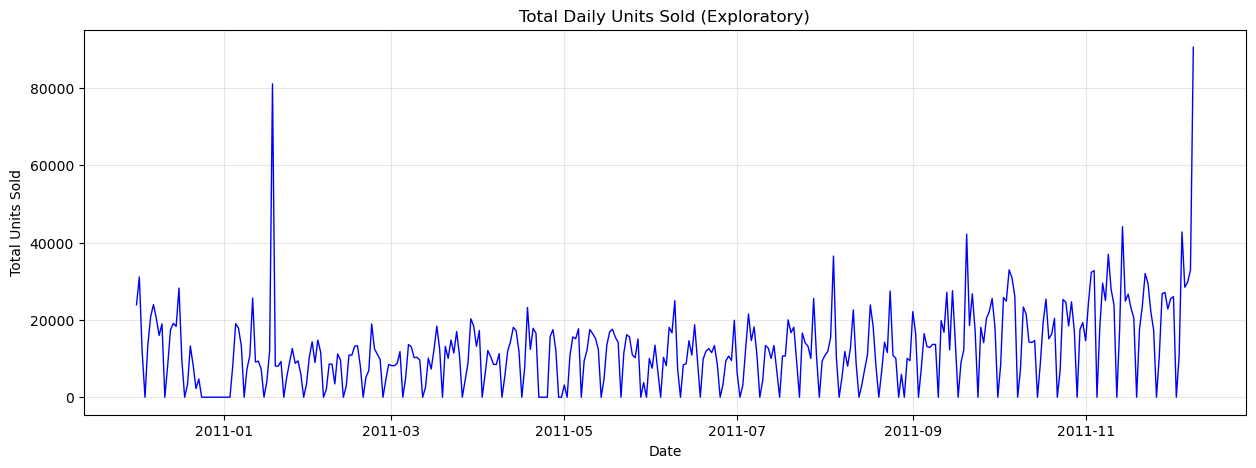

In [15]:
daily_totals = df_final.groupby("Date")["UnitsSold"].sum()

plt.figure(figsize=(15, 5))
plt.plot(daily_totals.index, daily_totals.values, color='blue', linewidth=1)
plt.title("Total Daily Units Sold (Exploratory)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(True, alpha=0.3)
plt.show()

## Step 16 — Final dataset
Format to only include `StockCode`, `Date`, `UnitsSold`, sorted logically.

In [16]:
df_final = df_final[["StockCode", "Date", "UnitsSold"]]
df_final = df_final.sort_values(by=["StockCode", "Date"]).reset_index(drop=True)

print("Final dataset ready:\n")
display(df_final.head())
display(df_final.tail())

Final dataset ready:



,StockCode,Date,UnitsSold
0,10002,2010-12-01,12
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-04,0
4,10002,2010-12-05,1


,StockCode,Date,UnitsSold
1464579,m,2011-12-05,0
1464580,m,2011-12-06,0
1464581,m,2011-12-07,0
1464582,m,2011-12-08,0
1464583,m,2011-12-09,0


## Step 17 — Save the processed dataset
Save to `data/processed_daily_sales.csv` and verify it loads correctly.

In [17]:
output_dir = Path(r"C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data")
output_dir.mkdir(exist_ok=True)
output_path = output_dir / "processed_daily_sales.csv"

df_final.to_csv(output_path, index=False)
print(f"Saved processed dataset to: {output_path.resolve()}")

# Verification reload
test_load = pd.read_csv(output_path)
print("\nVerified load shape:", test_load.shape)

Saved processed dataset to: C:\Users\ramganesh\OneDrive\Documents\SEM-3 PROJECTS\main project\smart-inventory-ai\data\processed_daily_sales.csv

Verified load shape: (1464584, 3)


C:\Users\ramganesh\AppData\Local\Temp\ipykernel_24288\2517583714.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  test_load = pd.read_csv(output_path)


## Summary

1. **Preprocessing Performed**: Loaded UCI retail data, filtered to a single-shop scope (UK), cleaned cancellations and erroneous negative values, extracted dates, aggregated sales daily per product, and expanded the timeline into a complete product-date calendar filling non-transaction days with zeros.
2. **Why it was necessary**: Real-world transaction logs are messy and incomplete. Creating a complete date calendar avoids ignoring "zero-sales" days, which are crucial for accurate demand forecasting.
3. **What the final dataset represents**: A daily ledger (`StockCode`, `Date`, `UnitsSold`) of historical sales for every product across the entire active timeline.
4. **Next Steps**: In `02_baseline.ipynb`, we will define the future 7-day demand target, split the data chronologically, and evaluate simple baseline heuristics before building complex models.